<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW12EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4.2 Graph Modeling

Any graph consists of both a set of objects, called nodes, and the connections between these nodes, called edges. Mathematically, a graph $G$ is denoted as pair $G(V, E)$, where $V = \{v_1, v_2, \ldots, v_n\}$ represents the set of nodes and $E = \{e_1, e_2, \ldots, e_m\}$ represents the set of edges and the size of the set is commonly shown as $m = |E|$. Edges are also represented by their endpoints (nodes), so $e(v_1, v_2)$ or $(v_1, v_2)$ defines an edge between nodes $v_1$ and $v_2$.

A sequence of edges where nodes and edges are distinct, $e_1(v_1, v_2)$, $e_2(v_2, v_3)$, $e_3(v_3, v_4)$, $\ldots$, $e_i(v_i, v_{i+1})$, is called a path. A closed path is called a cycle.

For a connected graph, multiple paths can exist between any pair of nodes. Often, we are interested in the path that has the shortest length. We will also use the shortest path as the distance for modeling on networks.

A graph with $n$ nodes can be represented by an $n \times n$ adjacency matrix. A value of 1 at row $i$, column $j$ in the adjacency matrix indicates a connection between nodes $v_i$ and $v_j$, and a value of 0 denotes no connection between the two nodes.

Consider a weighted graph $G = (V, E)$ with $n$ vertices and $m$ edges each with weights $E_{i,j}$ connecting nodes $i, j$. The adjacency matrix $M$ of a graph is defined by $M_{ij} = E_{ij}$ if there is an edge $\{i,j\}$ and $M_{ij} = 0$, otherwise. The Laplacian matrix $L$ of $G$ is an $n$ by $n$ symmetric matrix, with one row and column for each vertex, such that:

$$
L_{ij} =
\begin{cases}
\displaystyle\sum_k E_{ik}, & i = j, \\[6pt]
-E_{ij}, & i \neq j,\text{ and }v_i\text{ is adjacent to }v_j, \\[6pt]
0, & \text{otherwise}.
\end{cases}
$$

In addition, an $n \times m$ incidence matrix of $G$, denoted by $I_G$, has one row per vertex and one column per edge.

$\{i,j\}$ of $I_G$ is zero except the $i$th and $j$th entries, which are $\sqrt{E_{ij}}$ and $-\sqrt{E_{ij}}$, respectively.

### Theorem 4.2.3

The Laplacian matrix $L$ has the following properties:

1. $L = D - M$, where $M$ is the adjacency matrix and $D$ is the diagonal degree matrix with

   $$
   D_{ii} = \sum_k E_{ik}.
   $$

2. $L = I_G I_G^T$.

3. $L$ is symmetric positive semi-definite. All eigenvalues of $L$ are real and non-negative, and $L$ has a full set of $n$ real and orthogonal eigenvectors.

4. Let $e = [1, \ldots, 1]^T$. Then $Le = 0$. Thus 0 is the smallest eigenvalue and $e$ is the corresponding eigenvector.

5. If the graph $G$ has $c$ connected components, then $L$ has $c$ eigenvalues that are 0.

6. For any vector $x$,

   $$
   x^T Lx = \sum_{\{i,j\}\in E} E_{ij}(x_i - x_j)^2.
   $$

7. For any vector $x$ and scalars $\alpha, \beta$,

   $$
   (\alpha x + \beta e)^T L(\alpha x + \beta e)
   = \alpha^2 x^T Lx.
   $$

8. The problem

   $$
   \min_{x \neq 0} x^T Lx,
   \qquad
   \text{subject to } x^T x = 1,\quad x^T e = 0,
   \tag{4.2.2}
   $$

   is solved when $x$ is the eigenvector corresponding to the second smallest eigenvalue (the Fiedler vector) $\lambda_2$ of the eigenvalue problem

   $$
   Lx = \lambda x.
   $$

### Theorem 4.2.4 (Courant–Fischer theorem)

Let $A$ be an $n \times n$ symmetric matrix with an orthogonal diagonalization $A = PDP^{-1}$. The columns of $P$ are orthonormal eigenvectors $v_1, \ldots, v_n$ of $A$. Assume that the diagonal of $D$ is arranged so that

$$
\lambda_1 \leq \lambda_2 \leq \cdots \leq \lambda_n.
$$

Let $S_k$ be the span of $v_1, \ldots, v_k$ and $S_k^\perp$ denote the orthogonal complement of $S_k$. Then

$$
\min_{\substack{x \neq 0 \\ x \in S_{k-1}^{\perp}}}
\frac{x^T A x}{x^T x}
=
\lambda_k.
$$

### Corollary 4.2.5

Let $A$ be an $n \times n$ symmetric matrix with the orthogonal diagonalization $A = PDP^{-1}$. The columns of $P$ are orthonormal eigenvectors $v_1, \ldots, v_n$ of $A$. Assume that the diagonal of $D$ is arranged so that

$$
\lambda_1 \leq \lambda_2 \leq \cdots \leq \lambda_n.
$$

Then

$$
\min_{\substack{x \neq 0 \\ x^T v_1 = 0}}
\frac{x^T A x}{x^T x}
=
\lambda_2.
$$

In [1]:
# Imports
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

Nodes V:
[1, 2, 3, 4]

Edges E:
[(1, 2, {'weight': 1}), (1, 3, {'weight': 2}), (2, 3, {'weight': 3}), (3, 4, {'weight': 1})]


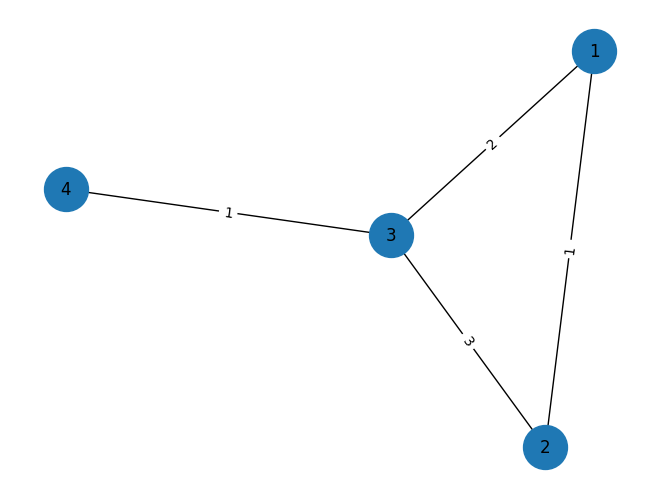


Adjacency Matrix M:
[[0. 1. 2. 0.]
 [1. 0. 3. 0.]
 [2. 3. 0. 1.]
 [0. 0. 1. 0.]]

Degree Matrix D:
[[3. 0. 0. 0.]
 [0. 4. 0. 0.]
 [0. 0. 6. 0.]
 [0. 0. 0. 1.]]

Laplacian Matrix L:
[[ 3. -1. -2.  0.]
 [-1.  4. -3.  0.]
 [-2. -3.  6. -1.]
 [ 0.  0. -1.  1.]]

Check L = D - M:
True

Eigenvalues of L:
[-1.97019169e-16  1.20140936e+00  4.31907245e+00  8.47951819e+00]

Eigenvectors of L:
[[-0.5        -0.36794634 -0.7554356  -0.20960091]
 [-0.5        -0.31652784  0.62601286 -0.5078563 ]
 [-0.5        -0.1726285   0.18523071  0.82818415]
 [-0.5         0.85710269 -0.05580798 -0.11072694]]

e:
[1. 1. 1. 1.]

L @ e:
[0. 0. 0. 0.]

Second-smallest eigenvalue (lambda_2):
1.201409359800576

Fiedler vector:
[-0.36794634 -0.31652784 -0.1726285   0.85710269]

All simple paths from node 1 to node 4:
[1, 2, 3, 4]
[1, 3, 4]

Weighted shortest path from 1 to 4:
[1, 3, 4]

Shortest distance:
3


In [2]:
# Create a small weighted graph G = (V, E)
G = nx.Graph()
# V = set of nodes
G.add_nodes_from([1, 2, 3, 4])
# E = set of edges
G.add_weighted_edges_from([
    (1, 2, 1),
    (1, 3, 2),
    (2, 3, 3),
    (3, 4, 1)
])
print("Nodes V:")
print(list(G.nodes()))
print("\nEdges E:")
print(list(G.edges(data=True)))

# Now lets draw the graph
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1000,
    font_size=12
)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
plt.show()

# Adjacency Matrix M
nodes = [1, 2, 3, 4]
M = nx.to_numpy_array(
    G,
    nodelist=nodes,
    weight="weight"
)
print("\nAdjacency Matrix M:")
print(M)

# D matrix
degrees = np.sum(M, axis=1)
D = np.diag(degrees)
print("\nDegree Matrix D:")
print(D)

# Laplacian Matrix L
L = D - M
print("\nLaplacian Matrix L:")
print(L)

# 6. Verify L = D - M
print("\nCheck L = D - M:")
print(np.allclose(L, D - M))
eigenvalues, eigenvectors = np.linalg.eigh(L)
print("\nEigenvalues of L:")
print(eigenvalues)
print("\nEigenvectors of L:")
print(eigenvectors)
e = np.ones(4)
print("\ne:")
print(e)
print("\nL @ e:")
print(L @ e)

# 9. Fiedler vector (the Eigenvector corresponding to second-smallest eigenvalue_
fiedler_value = eigenvalues[1]
fiedler_vector = eigenvectors[:, 1]
print("\nSecond-smallest eigenvalue (lambda_2):")
print(fiedler_value)
print("\nFiedler vector:")
print(fiedler_vector)


print("\nAll simple paths from node 1 to node 4:")
for path in nx.all_simple_paths(G, source=1, target=4):
    print(path)
shortest_path = nx.shortest_path(
    G,
    source=1,
    target=4,
    weight="weight"
)
shortest_distance = nx.shortest_path_length(
    G,
    source=1,
    target=4,
    weight="weight"
)
print("\nWeighted shortest path from 1 to 4:")
print(shortest_path)
print("\nShortest distance:")
print(shortest_distance)

## Quantum Mechanical Example: Tight-Binding Model

As a simple solid-state example, consider an electron moving through a one-dimensional chain of $N$ atomic sites. We can represent the atomic lattice as a graph, where each **node represents an atomic site** and each **edge represents the ability of an electron to hop between neighboring sites**.

For a chain of five atoms, the graph has the form

$$
1 - 2 - 3 - 4 - 5.
$$

The connectivity of the lattice can be described using the adjacency matrix $M$, where

$$
M_{ij} =
\begin{cases}
1, & \text{if sites } i \text{ and } j \text{ are neighbors},\\
0, & \text{otherwise}.
\end{cases}
$$

For the five-site chain,

$$
M =
\begin{bmatrix}
0 & 1 & 0 & 0 & 0\\
1 & 0 & 1 & 0 & 0\\
0 & 1 & 0 & 1 & 0\\
0 & 0 & 1 & 0 & 1\\
0 & 0 & 0 & 1 & 0
\end{bmatrix}.
$$

In the tight-binding approximation, the electron is assumed to be primarily localized around individual atomic sites but can hop between neighboring sites. The Hamiltonian can be written as

$$
H = \epsilon I - tM,
$$

where $\epsilon$ is the on-site energy, $t$ is the hopping strength, $I$ is the identity matrix, and $M$ is the adjacency matrix of the lattice.

For $\epsilon = 0$, the Hamiltonian becomes

$$
H = -tM.
$$

For the five-site chain,

$$
H =
-t
\begin{bmatrix}
0 & 1 & 0 & 0 & 0\\
1 & 0 & 1 & 0 & 0\\
0 & 1 & 0 & 1 & 0\\
0 & 0 & 1 & 0 & 1\\
0 & 0 & 0 & 1 & 0
\end{bmatrix}.
$$

The allowed quantum states are found by solving the time-independent Schrödinger equation

$$
H\psi_n = E_n\psi_n,
$$

where $E_n$ is an allowed energy and $\psi_n$ is the corresponding wavefunction.

For a five-site system, a state can be represented as

$$
\psi_n =
\begin{bmatrix}
\psi_1\\
\psi_2\\
\psi_3\\
\psi_4\\
\psi_5
\end{bmatrix}.
$$

The component $\psi_i$ describes the amplitude of the wavefunction at atomic site $i$, so

$$
|\psi_i|^2
$$

gives the probability of finding the electron at that site.

### Connection to the Graph Laplacian

The graph Laplacian can also be constructed from the adjacency matrix:

$$
L = D - M,
$$

where $D$ is the degree matrix.

A related graph-based Hamiltonian can be defined as

$$
H_L = tL.
$$

This Laplacian Hamiltonian is not, in general, identical to the standard tight-binding Hamiltonian $H = -tM$. Instead,

$$
H_L = t(D-M) = tD - tM.
$$

For a regular lattice, where every site has the same degree $d$,

$$
D = dI,
$$

and therefore

$$
H_L = tdI - tM.
$$

In this case, the Laplacian Hamiltonian and the tight-binding Hamiltonian differ only by the constant energy shift $tdI$, so they have the same eigenvectors.

The graph Laplacian provides a discrete analogue of the spatial derivative appearing in the kinetic-energy operator of the continuous Schrödinger equation,

$$
\hat{H}_{\mathrm{kin}}
=
-\frac{\hbar^2}{2m}\nabla^2.
$$

The continuous Laplacian $\nabla^2$ describes how the wavefunction varies in space, while the graph Laplacian describes how amplitudes vary between connected nodes.

Thus, the graph representation provides a direct connection between the **geometry and connectivity of the atomic lattice**, the **Hamiltonian matrix**, and the resulting **quantum energy states and wavefunctions**.

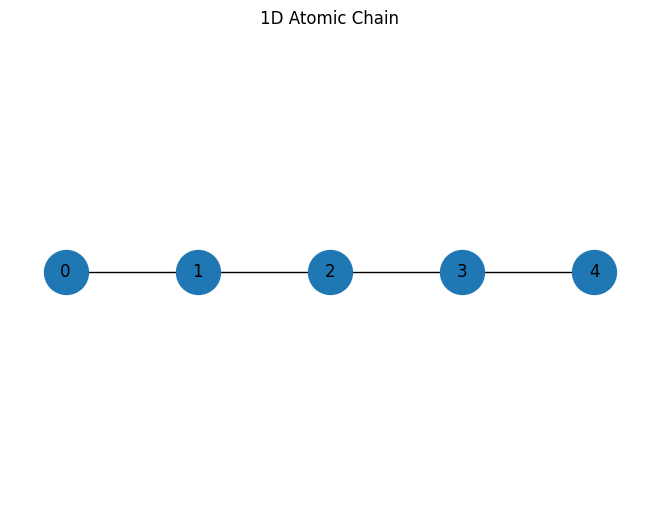

Adjacency matrix M:
[[0. 1. 0. 0. 0.]
 [1. 0. 1. 0. 0.]
 [0. 1. 0. 1. 0.]
 [0. 0. 1. 0. 1.]
 [0. 0. 0. 1. 0.]]

Degree matrix D:
[[1. 0. 0. 0. 0.]
 [0. 2. 0. 0. 0.]
 [0. 0. 2. 0. 0.]
 [0. 0. 0. 2. 0.]
 [0. 0. 0. 0. 1.]]

Graph Laplacian L:
[[ 1. -1.  0.  0.  0.]
 [-1.  2. -1.  0.  0.]
 [ 0. -1.  2. -1.  0.]
 [ 0.  0. -1.  2. -1.]
 [ 0.  0.  0. -1.  1.]]

Tight-binding Hamiltonian H:
[[ 0. -1.  0.  0.  0.]
 [-1.  0. -1.  0.  0.]
 [ 0. -1.  0. -1.  0.]
 [ 0.  0. -1.  0. -1.]
 [ 0.  0.  0. -1.  0.]]

Allowed energies:
[-1.73205081e+00 -1.00000000e+00 -1.02971082e-16  1.00000000e+00
  1.73205081e+00]


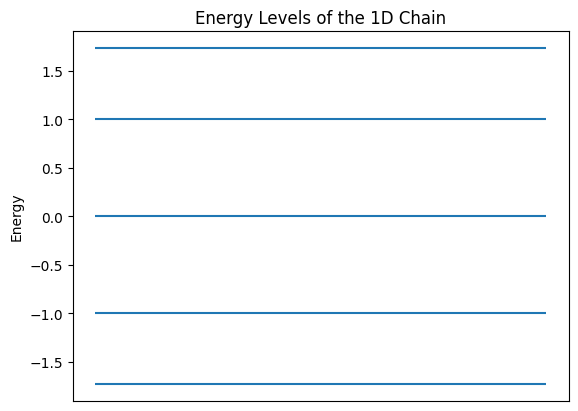


Ground-state wavefunction:
[-0.28867513 -0.5        -0.57735027 -0.5        -0.28867513]

Probability at each atomic site:
[0.08333333 0.25       0.33333333 0.25       0.08333333]


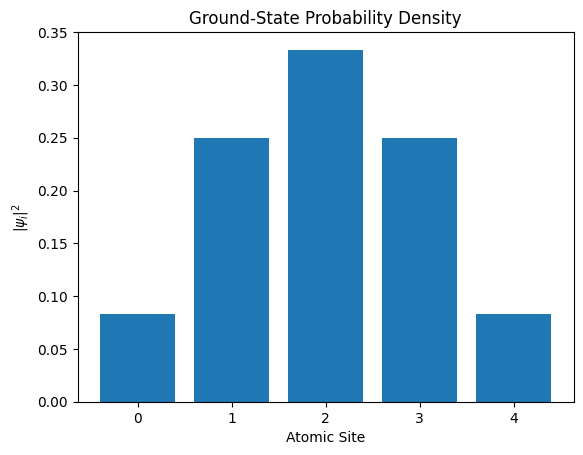

In [3]:
N = 5                 # number of atomic sites
t = 1.0               # hopping strength
epsilon = 0.0         # on-site energy

G = nx.Graph()
G.add_nodes_from(range(N))
for i in range(N - 1):
    G.add_edge(i, i + 1)
pos = {i: (i, 0) for i in range(N)}
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1000,
    font_size=12
)
plt.title("1D Atomic Chain")
plt.show()

M = nx.to_numpy_array(G)
print("Adjacency matrix M:")
print(M)
D = np.diag(np.sum(M, axis=1))
L = D - M
print("\nDegree matrix D:")
print(D)
print("\nGraph Laplacian L:")
print(L)

# Tight-binding Hamiltonian
H = epsilon * np.eye(N) - t * M
print("\nTight-binding Hamiltonian H:")
print(H)
# Solve the time-independent Schrodinger EQ
energies, wavefunctions = np.linalg.eigh(H)
print("\nAllowed energies:")
print(energies)

for E in energies:
    plt.hlines(E, 0, 1)
plt.ylabel("Energy")
plt.xticks([])
plt.title("Energy Levels of the 1D Chain")
plt.show()

# Look at the ground-state wavefunction
psi = wavefunctions[:, 0]
print("\nGround-state wavefunction:")
print(psi)
print("\nProbability at each atomic site:")
print(np.abs(psi)**2)

# Plot probability density
sites = np.arange(N)
plt.bar(sites, np.abs(psi)**2)
plt.xlabel("Atomic Site")
plt.ylabel(r"$|\psi_i|^2$")
plt.title("Ground-State Probability Density")
plt.show()